## 02_NLP_Transformers_Embeddings_ZeroShot_QA


> **Nota:** Todos los modelos usados en esta notebook son **gratuitos y de código abierto**,  
> disponibles en [huggingface.co/models](https://huggingface.co/models). No se requiere API key.


Instalamos las librerías necesarias. Si estás en **Google Colab**, estas celdas funcionan directo.  
En un entorno local, podés también correr `pip install -r requirements.txt`.


In [1]:
# Instalación de dependencias

!pip install transformers datasets sentence-transformers scikit-learn torch --quiet
!pip install accelerate evaluate --quiet

print("✅ Si no hubo errores, las librerías están listas.")


ERROR: Could not install packages due to an OSError: [Errno 28] No space left on device


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\Usuario\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


✅ Si no hubo errores, las librerías están listas.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\Usuario\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [ ]:
# Importaciones principales
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

print("✅ Librerías importadas correctamente.")


---
##Embeddings con Sentence Transformers
Un **embedding** es una representación numérica densa de un texto en un espacio vectorial de alta dimensión.  
Textos con significado similar quedan "cerca" en ese espacio.

```
"El gato come pescado"  →  [0.23, -0.81, 0.04, ..., 0.67]  # vector de 384 dimensiones
"El felino se alimenta de pez"  →  [0.25, -0.79, 0.01, ..., 0.65]  # ¡muy cercano!
"El mercado de acciones subió"  →  [-0.44, 0.33, 0.88, ..., -0.12]  # muy lejano
```

Vamos a usar `sentence-transformers`, una librería que expone modelos preentrenados  
especialmente diseñados para producir embeddings de buena calidad.


In [ ]:
from sentence_transformers import SentenceTransformer

# Cargamos un modelo multilingüe liviano (~120 MB)
# 'paraphrase-multilingual-MiniLM-L12-v2' funciona bien en español
model_emb = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

print(f"✅ Modelo cargado: {model_emb.get_sentence_embedding_dimension()} dimensiones")


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✅ Modelo cargado: 384 dimensiones


In [ ]:
# Oraciones de ejemplo en español
oraciones = [
    "El gato come pescado en el jardín",
    "El felino se alimenta de pez",
    "La economía argentina registró inflación",
    "Los precios subieron en el mercado",
    "El fútbol es el deporte más popular",
    "El balompié convoca millones de fanáticos",
    "Mañana llueve en Buenos Aires",
]

# Generamos embeddings (una sola llamada para todas las oraciones)
embeddings = model_emb.encode(oraciones)

print(f"Shape de la matriz de embeddings: {embeddings.shape}")
print(f"→ {len(oraciones)} oraciones × {embeddings.shape[1]} dimensiones")


Shape de la matriz de embeddings: (7, 384)
→ 7 oraciones × 384 dimensiones


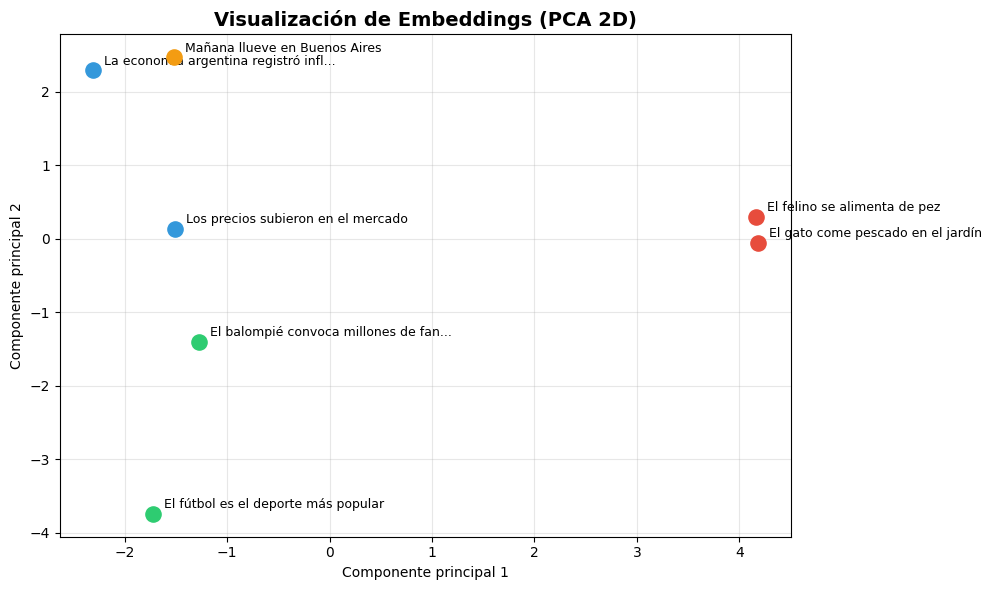

💡 Observá cómo oraciones semánticamente similares se agrupan en el espacio.


In [ ]:
# Visualización con PCA (reducimos de 384D a 2D para graficar)
pca = PCA(n_components=2)
coords = pca.fit_transform(embeddings)

colores = ["#e74c3c", "#e74c3c",    # gato / felino → rojo
           "#3498db", "#3498db",    # economía / precios → azul
           "#2ecc71", "#2ecc71",    # fútbol / balompié → verde
           "#f39c12"]               # lluvia → naranja

fig, ax = plt.subplots(figsize=(10, 6))
for i, (x, y) in enumerate(coords):
    ax.scatter(x, y, color=colores[i], s=120, zorder=5)
    ax.annotate(
        oraciones[i][:35] + ("..." if len(oraciones[i]) > 35 else ""),
        (x, y), textcoords="offset points", xytext=(8, 4), fontsize=9
    )

ax.set_title("Visualización de Embeddings (PCA 2D)", fontsize=14, fontweight="bold")
ax.set_xlabel("Componente principal 1")
ax.set_ylabel("Componente principal 2")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("embeddings_pca.png", dpi=120)
plt.show()
print("💡 Observá cómo oraciones semánticamente similares se agrupan en el espacio.")


---
## 📐 Sección 3 — Similaridad semántica

La **similitud coseno** mide el ángulo entre dos vectores.  
Valor 1 → textos idénticos en significado. Valor 0 → sin relación. Valor -1 → opuestos.

Esto es la base de motores de búsqueda semántica, sistemas de recomendación y RAG.


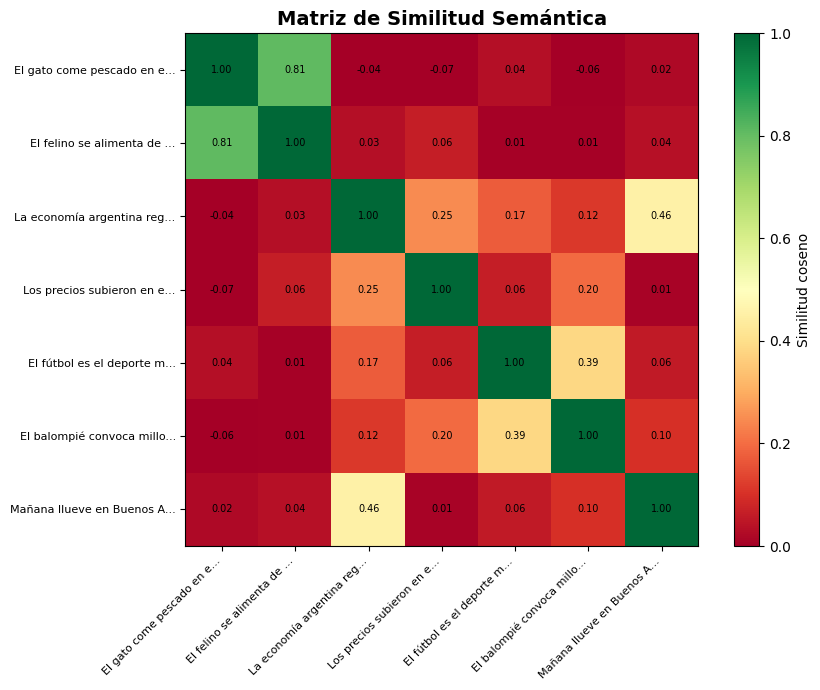

In [6]:
# Calculamos la matriz de similitud coseno entre todas las oraciones
sim_matrix = cosine_similarity(embeddings)

# Visualizamos como heatmap
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(sim_matrix, cmap="RdYlGn", vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label="Similitud coseno")

etiquetas = [o[:25] + "..." if len(o) > 25 else o for o in oraciones]
ax.set_xticks(range(len(oraciones)))
ax.set_yticks(range(len(oraciones)))
ax.set_xticklabels(etiquetas, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(etiquetas, fontsize=8)

# Escribimos los valores dentro del heatmap
for i in range(len(oraciones)):
    for j in range(len(oraciones)):
        ax.text(j, i, f"{sim_matrix[i,j]:.2f}", ha="center", va="center",
                fontsize=7, color="black")

ax.set_title("Matriz de Similitud Semántica", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("similitud_coseno.png", dpi=120)
plt.show()


In [7]:
# ─── Búsqueda semántica simple ───────────────────────────────────────────
def busqueda_semantica(query, corpus, model, umbral=0.3):
    """Dada una consulta, retorna las oraciones del corpus por encima del umbral de similitud."""
    query_emb = model.encode([query])
    corpus_emb = model.encode(corpus)
    sims = cosine_similarity(query_emb, corpus_emb)[0]
    indices = np.argsort(sims)[::-1]
    resultados = [(idx, sims[idx]) for idx in indices if sims[idx] >= umbral]

    print(f"\n🔍 Query: '{query}'  (umbral: {umbral})\n")
    if not resultados:
        print("  ⚠️  Ninguna oración superó el umbral.")
        return
    print(f"{'Pos':>3}  {'Similitud':>9}  Resultado")
    print("-" * 60)
    for rank, (idx, sim) in enumerate(resultados, 1):
        print(f"{rank:>3}  {sim:>9.4f}  {corpus[idx]}")

corpus = [
    "El presidente firmó un decreto económico",
    "La selección argentina ganó el partido",
    "Suben los precios de los alimentos básicos",
    "El técnico planteó una defensa sólida",
    "El Banco Central intervino en el mercado cambiario",
    "Messi marcó un doblete en el último encuentro",
    "La inflación mensual superó las expectativas",
]

# ── Modificá el umbral a tu criterio (entre 0 y 1) ───────────────────────
UMBRAL = 0.5

busqueda_semantica("¿Cómo está la economía?", corpus, model_emb, umbral=UMBRAL)
busqueda_semantica("Resultados del campeonato de fútbol", corpus, model_emb, umbral=UMBRAL)



🔍 Query: '¿Cómo está la economía?'  (umbral: 0.5)

  ⚠️  Ninguna oración superó el umbral.

🔍 Query: 'Resultados del campeonato de fútbol'  (umbral: 0.5)

Pos  Similitud  Resultado
------------------------------------------------------------
  1     0.5468  La selección argentina ganó el partido


In [8]:
# Escribí tu propia query y observá los resultados

mi_query = "qué alimentos no contienen carbohidratos"  # ← MODIFICÁ ESTO
UMBRAL = 0.4

busqueda_semantica(mi_query, corpus, model_emb)



🔍 Query: 'qué alimentos no contienen carbohidratos'  (umbral: 0.3)

Pos  Similitud  Resultado
------------------------------------------------------------
  1     0.3691  Suben los precios de los alimentos básicos


---
## 🚀 Sección 4 — Pipelines de Hugging Face

La API `pipeline` de Hugging Face es la forma más rápida de usar modelos preentrenados.  
Con una sola línea descargás y usás modelos para tareas como:

- **Clasificación de texto** (sentiment analysis, detección de temas)
- **Generación de texto** (completar oraciones, chatbots)
- **Question Answering** (responder preguntas dado un contexto)
- **Resumen automático** (summarization)
- **Traducción**

### ¿Cómo funciona internamente?

```
Texto → Tokenización → Modelo Transformer → Cabeza de tarea → Predicción
         (WordPiece)    (BERT, RoBERTa...)   (clasificador)
```


In [9]:
from transformers import pipeline

# ── 4.1 Análisis de sentimiento ──────────────────────────────────────────
# Usamos un modelo entrenado en español
print("⏳ Cargando modelo de sentimiento en español...")
sentimiento = pipeline(
    "text-classification",
    model="nlptown/bert-base-multilingual-uncased-sentiment"
)

textos = [
    "¡Excelente producto! Lo recomiendo totalmente.",
    "Muy mala experiencia, nunca más compro acá.",
    "El servicio fue aceptable, ni bueno ni malo.",
    "Llegó tarde pero funcionó bien.",
]

print("\n📊 Análisis de Sentimiento\n")
print(f"{'Texto':<45} {'Resultado':<15} {'Confianza':>9}")
print("-" * 72)
for texto in textos:
    resultado = sentimiento(texto)[0]
    estrellas = resultado["label"]
    conf = resultado["score"]
    print(f"{texto[:44]:<45} {estrellas:<15} {conf:>9.2%}")


⏳ Cargando modelo de sentimiento en español...


config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


📊 Análisis de Sentimiento

Texto                                         Resultado       Confianza
------------------------------------------------------------------------
¡Excelente producto! Lo recomiendo totalment  5 stars            90.31%
Muy mala experiencia, nunca más compro acá.   1 star             91.14%
El servicio fue aceptable, ni bueno ni malo.  3 stars            47.20%
Llegó tarde pero funcionó bien.               3 stars            49.73%


In [10]:
# ── 4.3 Zero-shot classification ─────────────────────────────────────────
# Clasificamos texto en categorías que NUNCA vio el modelo durante el entrenamiento
print("⏳ Cargando modelo zero-shot...")
zero_shot = pipeline(
    "zero-shot-classification",
    model="joeddav/xlm-roberta-large-xnli"
)

noticias = [
    "El gobierno anunció medidas para reducir el déficit fiscal.",
    "La selección venció 3-0 en el clásico del domingo.",
    "Científicos descubren nueva variante del virus en Europa.",
    "Apple presentó su nuevo dispositivo con chip de última generación.",
]

categorias = ["política", "deportes", "salud", "tecnología", "economía"]

print("\n🏷️  Clasificación Zero-Shot\n")
for noticia in noticias:
    res = zero_shot(noticia, candidate_labels=categorias)
    top_label = res["labels"][0]
    top_score = res["scores"][0]
    print(f"📰 {noticia[:55]}...")
    print(f"   → {top_label.upper()} ({top_score:.2%})\n")


⏳ Cargando modelo zero-shot...


config.json:   0%|          | 0.00/734 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]


🏷️  Clasificación Zero-Shot

📰 El gobierno anunció medidas para reducir el déficit fis...
   → ECONOMÍA (50.48%)

📰 La selección venció 3-0 en el clásico del domingo....
   → DEPORTES (67.89%)

📰 Científicos descubren nueva variante del virus en Europ...
   → TECNOLOGÍA (56.37%)

📰 Apple presentó su nuevo dispositivo con chip de última ...
   → TECNOLOGÍA (89.93%)



In [11]:
# 🧪 TU TURNO — Ejercicio 4.1
# Probá el clasificador zero-shot con tu propio texto y tus propias categorías

mi_texto = "pérdida de consciencia y sangrado abundante por herida abierta en miembro inferior"            # ← MODIFICÁ ESTO
mis_categorias = ["urgencia", "emergencia"]  # ← MODIFICÁ ESTO

resultado = zero_shot(mi_texto, candidate_labels=mis_categorias)
print(f"Texto: {mi_texto}")
print("\nResultados:")
for label, score in zip(resultado["labels"], resultado["scores"]):
    barra = "█" * int(score * 20)
    print(f"  {label:<15} {barra:<20} {score:.2%}")


Texto: pérdida de consciencia y sangrado abundante por herida abierta en miembro inferior

Resultados:
  emergencia      ████████████████     83.84%
  urgencia        ███                  16.16%


In [18]:
# ══════════════════════════════════════════════════════════════════════════
# Question Answering en dominio médico — español
# ══════════════════════════════════════════════════════════════════════════

from transformers import AutoTokenizer, AutoModelForQuestionAnswering
import torch

MODEL = 'mrm8488/bert-base-spanish-wwm-cased-finetuned-spa-squad2-es'

# 1. Cargamos el modelo y el tokenizador de forma explícita
print("⏳ Cargando modelo y tokenizador...")
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForQuestionAnswering.from_pretrained(MODEL)

# 2. Definimos el contexto clínico y la pregunta
contexto = """
La neumonía adquirida en la comunidad (NAC) es una infección aguda del parénquima
pulmonar adquirida fuera del entorno hospitalario. Los agentes etiológicos más
frecuentes son Streptococcus pneumoniae, Mycoplasma pneumoniae y virus respiratorios.
La clínica incluye fiebre, tos productiva, disnea y dolor pleurítico. El tratamiento
antibiótico empírico inicial suele ser amoxicilina o levofloxacino en casos moderados.
"""

pregunta = "¿Cuál es el tratamiento antibiótico empírico inicial?"

# 3. Procesamos los textos y obtenemos la predicción
inputs = tokenizer(pregunta, contexto, return_tensors="pt")
with torch.no_grad():
    outputs = model(**inputs)

# Obtener los logits de inicio y fin de la respuesta
start_logits = outputs.start_logits
end_logits = outputs.end_logits

# Encontrar los tokens con mayor probabilidad
answer_start = torch.argmax(start_logits)
answer_end = torch.argmax(end_logits) + 1

# Decodificar la respuesta predicha
respuesta = tokenizer.convert_tokens_to_string(
    tokenizer.convert_ids_to_tokens(inputs["input_ids"][0][answer_start:answer_end])
)

print("\n=== RESULTADO ===")
print(f"Pregunta: {pregunta}")
print(f"Respuesta: {respuesta}")

⏳ Cargando modelo y tokenizador...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForQuestionAnswering LOAD REPORT from: mrm8488/bert-base-spanish-wwm-cased-finetuned-spa-squad2-es
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



=== RESULTADO ===
Pregunta: ¿Cuál es el tratamiento antibiótico empírico inicial?
Respuesta: amoxicilina o levofloxacino
